# Física II — Parte II: Oscilações Harmônicas Amortecidas e Forçadas

**Engenharia Naval — Escola Politécnica da USP**

Este notebook dá continuidade ao estudo do Movimento Harmônico Simples (MHS) visto no notebook anterior
(`01_Movimento_Harmonico_Simples.ipynb`). Lá, consideramos sistemas *ideais*, sem perda de energia. Agora vamos
tornar o modelo mais realista: todo sistema oscilante real perde energia por atrito/dissipação (**amortecimento**)
e, frequentemente, está sujeito a uma força externa periódica que o excita continuamente (**oscilação forçada**).

Esses dois ingredientes — amortecimento e forçamento — são centrais em engenharia naval e offshore: o
comportamento de um casco sob ondas, a resposta estrutural de uma plataforma, o projeto de amortecedores e
sistemas de suspensão, e o fenômeno de **ressonância** (que pode ser catastrófico em estruturas) só são
compreendidos com essa teoria.

## Sumário

- [1. Oscilações amortecidas](#1.-Oscilações-amortecidas)
  - [1.1 Equação diferencial do oscilador amortecido](#1.1-Equação-diferencial-do-oscilador-amortecido)
  - [1.2 Solução geral e os três regimes](#1.2-Solução-geral-e-os-três-regimes)
  - [1.3 Amortecimento sub-crítico (subamortecido)](#1.3-Amortecimento-sub-crítico-(subamortecido))
  - [1.4 Amortecimento super-crítico (superamortecido)](#1.4-Amortecimento-super-crítico-(superamortecido))
  - [1.5 Amortecimento crítico e comparação dos três regimes](#1.5-Amortecimento-crítico-e-comparação-dos-três-regimes)
- [2. Oscilações forçadas](#2.-Oscilações-forçadas)
  - [2.1 Equação do oscilador forçado e solução estacionária](#2.1-Equação-do-oscilador-forçado-e-solução-estacionária)
  - [2.2 Curva de ressonância em amplitude](#2.2-Curva-de-ressonância-em-amplitude)
  - [2.3 Defasagem entre força e resposta](#2.3-Defasagem-entre-força-e-resposta)
  - [2.4 Ressonância: simulação dinâmica e exemplos reais](#2.4-Ressonância:-simulação-dinâmica-e-exemplos-reais)
  - [2.5 Papel das condições iniciais: transiente + estacionário](#2.5-Papel-das-condições-iniciais:-transiente-+-estacionário)
- [Resumo final](#Resumo-final)

> **Como usar este notebook:** é material de revisão visual — não há exercícios. Execute as células em ordem
> (`Kernel → Restart & Run All`) e explore os gráficos e animações. O foco é construir intuição física sobre como
> amplitude, fase e energia evoluem nesses sistemas.


## Setup inicial

Importamos as bibliotecas e configuramos o estilo visual que será usado em todos os gráficos do notebook.
Como não temos `scipy` disponível, qualquer integração numérica será feita "na mão" com `numpy`
(método de Euler-Cromer ou Runge-Kutta de 4ª ordem implementados manualmente).


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyArrowPatch
import sympy as sp
from IPython.display import HTML

plt.rcParams.update({
    'figure.figsize': (9, 5),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'font.size': 11,
    'lines.linewidth': 2.2,
    'legend.frameon': False,
})

# Paleta de cores consistente
COR_SUB = '#2E86AB'      # azul - subamortecido
COR_CRIT = '#06A77D'     # verde - crítico
COR_SUPER = '#D62246'    # vermelho - superamortecido
COR_ENV = '#F4A259'      # laranja - envelope
COR_FORCA = '#7D5BA6'    # roxo - força externa
COR_ENERGIA = '#C44536'  # vermelho queimado - energia

print('Ambiente configurado. numpy', np.__version__, '| sympy', sp.__version__)


Ambiente configurado. numpy 2.5.3 | sympy 1.14.0


## 1. Oscilações amortecidas

### 1.1 Equação diferencial do oscilador amortecido

No MHS ideal tínhamos $m\ddot{x} + kx = 0$. Agora incluímos uma força dissipativa proporcional à velocidade
(modelo razoável para atrito viscoso, amortecedores hidráulicos, arrasto em baixas velocidades etc.):

$$m\ddot{x} + b\dot{x} + kx = 0$$

onde $b>0$ é o **coeficiente de amortecimento**. Dividindo por $m$ e definindo

$$\omega_0^2 = \frac{k}{m} \qquad \text{(frequência natural)}, \qquad \gamma = \frac{b}{2m} \qquad \text{(taxa de amortecimento)}$$

a equação fica

$$\ddot{x} + 2\gamma\dot{x} + \omega_0^2 x = 0$$

Buscando soluções do tipo $x(t) = e^{\lambda t}$, obtemos a **equação característica**:

$$\lambda^2 + 2\gamma\lambda + \omega_0^2 = 0 \quad\Longrightarrow\quad \lambda = -\gamma \pm \sqrt{\gamma^2 - \omega_0^2}$$

O comportamento qualitativo da solução depende inteiramente do sinal do **discriminante** $\Delta = \gamma^2 - \omega_0^2$.
Vamos usar `sympy` para obter isso simbolicamente.


In [2]:
t, m, b, k, gamma, omega0, lam, A, B, phi = sp.symbols('t m b k gamma omega_0 lambda A B phi', positive=False)
x = sp.Function('x')

# Equação diferencial original
eq = sp.Eq(m*x(t).diff(t, 2) + b*x(t).diff(t) + k*x(t), 0)
display(eq)

# Equação característica em lambda, após substituir gamma = b/(2m), omega0^2 = k/m
char_eq = sp.Eq(lam**2 + 2*gamma*lam + omega0**2, 0)
display(char_eq)

raizes = sp.solve(char_eq, lam)
print('Raízes da equação característica:')
for r in raizes:
    display(sp.Eq(lam, r))

discriminante = sp.sqrt(gamma**2 - omega0**2)
print('\nDiscriminante (dentro da raiz): gamma^2 - omega_0^2')
print('  Delta > 0  (gamma > omega_0)  -> super-crítico (duas raízes reais negativas)')
print('  Delta = 0  (gamma = omega_0)  -> crítico (raiz dupla real)')
print('  Delta < 0  (gamma < omega_0)  -> sub-crítico (raízes complexas conjugadas)')


Eq(b*Derivative(x(t), t) + k*x(t) + m*Derivative(x(t), (t, 2)), 0)

Eq(2*gamma*lambda + lambda**2 + omega_0**2, 0)

Raízes da equação característica:


Eq(lambda, -gamma - sqrt((gamma - omega_0)*(gamma + omega_0)))

Eq(lambda, -gamma + sqrt((gamma - omega_0)*(gamma + omega_0)))


Discriminante (dentro da raiz): gamma^2 - omega_0^2
  Delta > 0  (gamma > omega_0)  -> super-crítico (duas raízes reais negativas)
  Delta = 0  (gamma = omega_0)  -> crítico (raiz dupla real)
  Delta < 0  (gamma < omega_0)  -> sub-crítico (raízes complexas conjugadas)


### 1.2 Solução geral e os três regimes

A solução geral da equação característica fornece três regimes físicos distintos, segundo a comparação entre
$\gamma$ (amortecimento) e $\omega_0$ (frequência natural):

| Regime | Condição | Forma da solução |
|---|---|---|
| **Subamortecido** | $\gamma < \omega_0$ | $x(t) = A e^{-\gamma t}\cos(\omega_d t + \phi)$, com $\omega_d = \sqrt{\omega_0^2 - \gamma^2}$ |
| **Criticamente amortecido** | $\gamma = \omega_0$ | $x(t) = (A + Bt)e^{-\gamma t}$ |
| **Superamortecido** | $\gamma > \omega_0$ | $x(t) = A e^{\lambda_1 t} + B e^{\lambda_2 t}$, com $\lambda_{1,2} = -\gamma \pm \sqrt{\gamma^2-\omega_0^2} < 0$ |

> **Intuição física:** pense em uma porta com dobradiça hidráulica. Se o amortecimento é fraco (sub-crítico), a
> porta bate e oscila várias vezes antes de parar. Se é forte demais (super-crítico), ela fecha devagar demais,
> "arrastando". O amortecimento crítico é o ajuste ótimo: fecha o mais rápido possível **sem** oscilar.

Vamos agora estudar cada regime em detalhe.


### 1.3 Amortecimento sub-crítico (subamortecido)

Quando $\gamma < \omega_0$, o sistema oscila com frequência $\omega_d = \sqrt{\omega_0^2-\gamma^2} < \omega_0$
(ligeiramente menor que a frequência natural) e amplitude decaindo exponencialmente:

$$x(t) = A e^{-\gamma t}\cos(\omega_d t + \phi)$$

A curva fica "presa" dentro de um **envelope exponencial** $\pm A e^{-\gamma t}$.


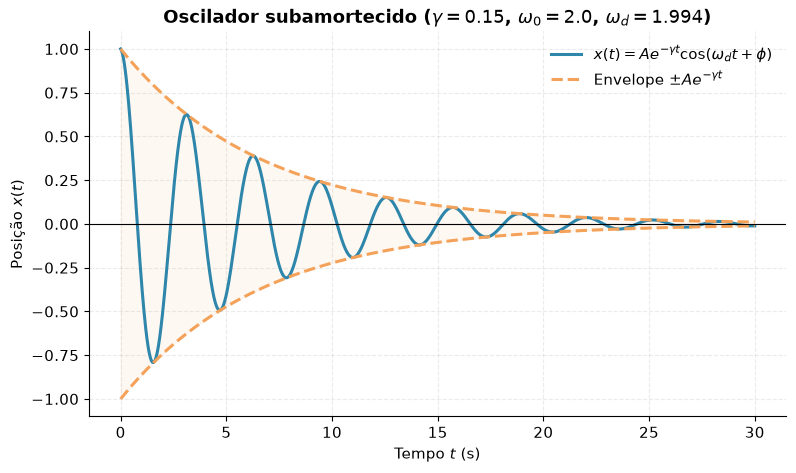

In [3]:
A0, gamma1, omega0_1, phi0 = 1.0, 0.15, 2.0, 0.0
omega_d1 = np.sqrt(omega0_1**2 - gamma1**2)

tt = np.linspace(0, 30, 2000)
xx = A0*np.exp(-gamma1*tt)*np.cos(omega_d1*tt + phi0)
env_pos = A0*np.exp(-gamma1*tt)
env_neg = -env_pos

fig, ax = plt.subplots()
ax.plot(tt, xx, color=COR_SUB, label=r'$x(t)=Ae^{-\gamma t}\cos(\omega_d t+\phi)$')
ax.plot(tt, env_pos, '--', color=COR_ENV, label=r'Envelope $\pm Ae^{-\gamma t}$')
ax.plot(tt, env_neg, '--', color=COR_ENV)
ax.fill_between(tt, env_neg, env_pos, color=COR_ENV, alpha=0.07)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Tempo $t$ (s)')
ax.set_ylabel('Posição $x(t)$')
ax.set_title(f'Oscilador subamortecido ($\\gamma={gamma1}$, $\\omega_0={omega0_1}$, $\\omega_d={omega_d1:.3f}$)')
ax.legend(loc='upper right')
plt.show()


#### Análise de energia

A energia mecânica total é $E(t) = \tfrac12 m\dot{x}^2 + \tfrac12 k x^2$. Para amortecimento fraco, a amplitude
decai como $e^{-\gamma t}$, então a energia (que vai com o quadrado da amplitude) decai aproximadamente como
$E(t) \approx E_0\, e^{-2\gamma t}$ — um decaimento exponencial bem mais rápido que o da amplitude.


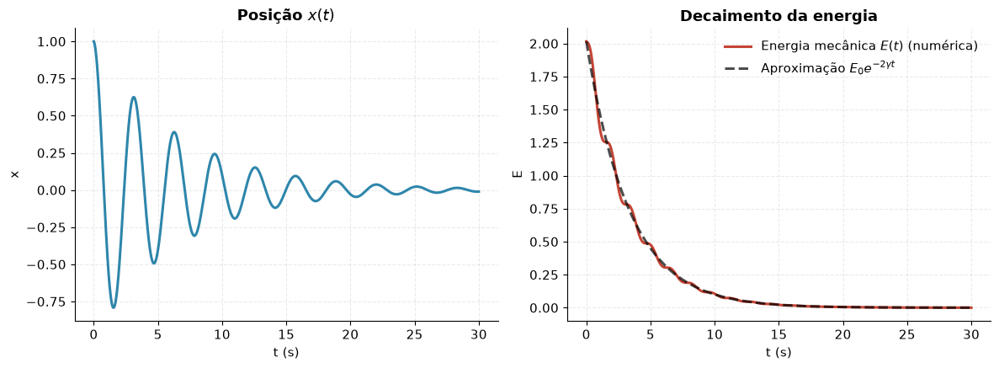

Fator de qualidade Q = omega0/(2*gamma) = 6.67
=> o sistema realiza ~1.06 oscilações completas antes que a ENERGIA decaia por um fator 1/e^(2π) ~ 1/535
   (regra prática: quanto maior Q, mais "ressonante" e menos amortecido é o sistema)


In [4]:
m_val, k_val = 1.0, omega0_1**2 * 1.0  # com m=1, k = omega0^2
b_val = 2*gamma1*m_val

# velocidade por diferenciação numérica (simples e suficiente aqui)
vv = np.gradient(xx, tt)
E = 0.5*m_val*vv**2 + 0.5*k_val*xx**2
E0 = E[0]
E_aprox = E0*np.exp(-2*gamma1*tt)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].plot(tt, xx, color=COR_SUB)
axs[0].set_title('Posição $x(t)$')
axs[0].set_xlabel('t (s)'); axs[0].set_ylabel('x')

axs[1].plot(tt, E, color=COR_ENERGIA, label='Energia mecânica $E(t)$ (numérica)')
axs[1].plot(tt, E_aprox, '--', color='k', alpha=0.7, label=r'Aproximação $E_0 e^{-2\gamma t}$')
axs[1].set_title('Decaimento da energia')
axs[1].set_xlabel('t (s)'); axs[1].set_ylabel('E')
axs[1].legend()
plt.tight_layout()
plt.show()

# Fator de qualidade Q
Q = omega0_1/(2*gamma1)
n_osc = Q/np.pi  # número aproximado de radianos/oscilações antes do decaimento de 1/e em energia
print(f'Fator de qualidade Q = omega0/(2*gamma) = {Q:.2f}')
print(f'=> o sistema realiza ~{Q/(2*np.pi):.2f} oscilações completas antes que a ENERGIA decaia por um fator 1/e^(2π) ~ 1/535')
print(f'   (regra prática: quanto maior Q, mais "ressonante" e menos amortecido é o sistema)')


O **fator de mérito (ou qualidade) $Q$** é definido como

$$Q = \frac{\omega_0}{2\gamma}$$

$Q$ mede quantos radianos de oscilação o sistema completa antes que a energia decaia significativamente: um
sino (alta $Q$, toca por muito tempo) *versus* uma porta com amortecedor (baixa $Q$, para quase imediatamente).
Em termos práticos, um sistema com $Q \gg 1$ oscila muitas vezes antes de parar; com $Q \sim 1$, já está na
fronteira entre oscilar e não oscilar.

> **Intuição física:** o fator $Q$ aparece em quase toda engenharia de vibração — de cordas de violino
> ($Q$ alto, o som "sustenta") a sistemas de suspensão veicular/naval ($Q$ baixo é desejado, para que o veículo
> não continue "balançando" após um solavanco).

Agora, uma animação do sistema massa-mola oscilando com amplitude visivelmente decrescente:


In [5]:
fig, (ax_osc, ax_x) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios':[1,2]})

# painel esquerdo: massa-mola vertical
ax_osc.set_xlim(-1.5, 1.5)
ax_osc.set_ylim(-1.3, 1.3)
ax_osc.set_xticks([]); ax_osc.set_yticks([])
ax_osc.set_title('Massa-mola amortecida')
teto, = ax_osc.plot([-0.4, 0.4], [1.1, 1.1], color='k', lw=4)
mola, = ax_osc.plot([], [], color='gray', lw=1.5)
massa = plt.Circle((0, 0), 0.14, color=COR_SUB, zorder=5)
ax_osc.add_patch(massa)

# painel direito: x(t) sendo traçado
ax_x.set_xlim(tt.min(), tt.max())
ax_x.set_ylim(-1.2, 1.2)
ax_x.plot(tt, env_pos, '--', color=COR_ENV, alpha=0.6)
ax_x.plot(tt, env_neg, '--', color=COR_ENV, alpha=0.6)
ax_x.axhline(0, color='k', lw=0.6)
ax_x.set_xlabel('t (s)'); ax_x.set_ylabel('x(t)')
linha_x, = ax_x.plot([], [], color=COR_SUB)
ponto_x, = ax_x.plot([], [], 'o', color=COR_SUB)

def mola_zigzag(y0, y1, n=10):
    ys = np.linspace(y0, y1, 2*n+1)
    xs = 0.18*np.array([0 if i==0 or i==len(ys)-1 else (1 if i%2 else -1) for i in range(len(ys))])
    return xs, ys

frames = np.arange(0, len(tt), 4)

def init():
    linha_x.set_data([], [])
    ponto_x.set_data([], [])
    return massa, mola, linha_x, ponto_x

def update(i):
    idx = frames[i]
    y_massa = 0.9*xx[idx]/A0  # escala visual
    xs_m, ys_m = mola_zigzag(1.1, y_massa+0.14)
    mola.set_data(xs_m, ys_m)
    massa.center = (0, y_massa)
    linha_x.set_data(tt[:idx], xx[:idx])
    ponto_x.set_data([tt[idx]], [xx[idx]])
    return massa, mola, linha_x, ponto_x

anim = animation.FuncAnimation(fig, update, frames=len(frames), init_func=init, interval=30, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())


Animation size has reached 21023149 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


### 1.4 Amortecimento super-crítico (superamortecido)

Quando $\gamma > \omega_0$, as duas raízes $\lambda_{1,2} = -\gamma \pm \sqrt{\gamma^2-\omega_0^2}$ são **reais e
negativas**. Não há oscilação: o sistema simplesmente relaxa de volta ao equilíbrio.

$$x(t) = A\,e^{\lambda_1 t} + B\,e^{\lambda_2 t}$$

Quanto maior o grau de amortecimento (maior $\gamma/\omega_0$), mais lento é o retorno ao equilíbrio (o termo
dominante $e^{\lambda_1 t}$, com $|\lambda_1|$ pequeno, domina em tempos longos).


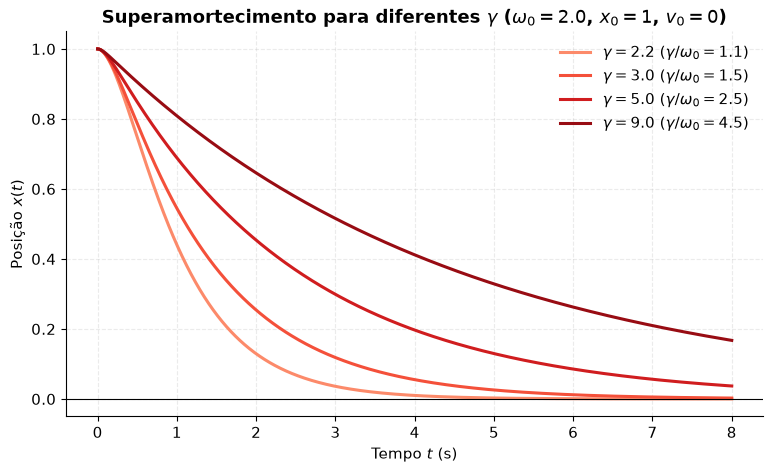

In [6]:
def superamortecido(t, gamma, omega0, x0=1.0, v0=0.0):
    disc = np.sqrt(gamma**2 - omega0**2)
    l1 = -gamma + disc
    l2 = -gamma - disc
    # condições iniciais x(0)=x0, v(0)=v0
    Bc = (v0 - l1*x0)/(l2 - l1)
    Ac = x0 - Bc
    return Ac*np.exp(l1*t) + Bc*np.exp(l2*t)

tt2 = np.linspace(0, 8, 1000)
omega0_2 = 2.0
gammas_super = [2.2, 3.0, 5.0, 9.0]

fig, ax = plt.subplots()
cmap = plt.cm.Reds(np.linspace(0.4, 0.9, len(gammas_super)))
for g, c in zip(gammas_super, cmap):
    y = superamortecido(tt2, g, omega0_2)
    ax.plot(tt2, y, color=c, label=fr'$\gamma={g}$ ($\gamma/\omega_0={g/omega0_2:.1f}$)')

ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Tempo $t$ (s)')
ax.set_ylabel('Posição $x(t)$')
ax.set_title(fr'Superamortecimento para diferentes $\gamma$ ($\omega_0={omega0_2}$, $x_0=1$, $v_0=0$)')
ax.legend()
plt.show()


> **Intuição física:** quanto mais "forte" o amortecimento super-crítico, mais devagar o sistema retorna ao
> equilíbrio — não porque "oscila menos", mas porque o atrito é tão dominante que dificulta até o próprio retorno.
> É como tentar fechar uma porta com um amortecedor hidráulico extremamente viscoso: ela demora para fechar de vez.


### 1.5 Amortecimento crítico e comparação dos três regimes

No limite exato $\gamma = \omega_0$ (raiz dupla), a solução geral é

$$x(t) = (A + Bt)\,e^{-\gamma t}$$

Esse é o regime de interesse prático em engenharia: ele representa o **retorno mais rápido possível ao
equilíbrio sem overshoot/oscilação**. É o princípio de projeto de amortecedores de suspensão (carros, trens de
pouso, e também sistemas de amortecimento de movimento em plataformas offshore e suspensões de equipamentos
embarcados), onde se deseja estabilizar rapidamente sem "balançar".

Vamos comparar os três regimes com as **mesmas condições iniciais** $x(0)=1,\ \dot x(0)=0$.


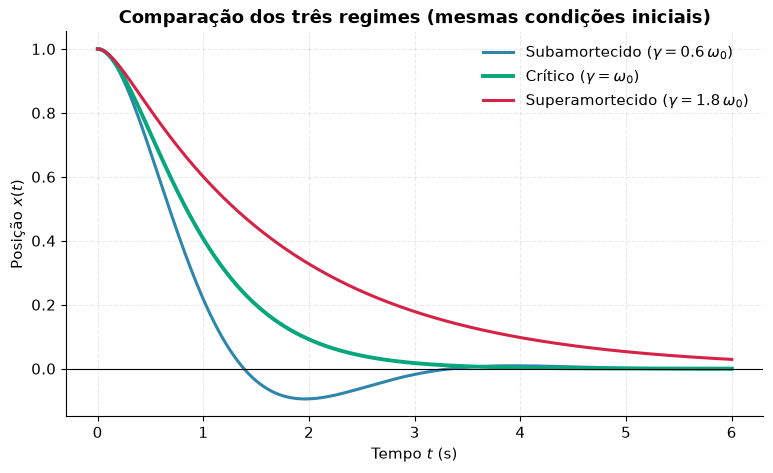

Note que o regime crítico é o que primeiro cruza/retorna perto de x=0, sem ultrapassar (overshoot)
de forma oscilatória, e sem a lentidão excessiva do superamortecido.


In [7]:
def subamortecido(t, gamma, omega0, x0=1.0, v0=0.0):
    wd = np.sqrt(omega0**2 - gamma**2)
    Ac = x0
    Bc = (v0 + gamma*x0)/wd
    return np.exp(-gamma*t)*(Ac*np.cos(wd*t) + Bc*np.sin(wd*t))

def critico(t, gamma, x0=1.0, v0=0.0):
    Ac = x0
    Bc = v0 + gamma*x0
    return (Ac + Bc*t)*np.exp(-gamma*t)

omega0_3 = 2.0
tt3 = np.linspace(0, 6, 1000)

y_sub = subamortecido(tt3, 0.6*omega0_3, omega0_3)
y_crit = critico(tt3, omega0_3)
y_super = superamortecido(tt3, 1.8*omega0_3, omega0_3)

fig, ax = plt.subplots()
ax.plot(tt3, y_sub, color=COR_SUB, label=r'Subamortecido ($\gamma=0.6\,\omega_0$)')
ax.plot(tt3, y_crit, color=COR_CRIT, label=r'Crítico ($\gamma=\omega_0$)', lw=2.8)
ax.plot(tt3, y_super, color=COR_SUPER, label=r'Superamortecido ($\gamma=1.8\,\omega_0$)')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Tempo $t$ (s)')
ax.set_ylabel('Posição $x(t)$')
ax.set_title('Comparação dos três regimes (mesmas condições iniciais)')
ax.legend()
plt.show()

print('Note que o regime crítico é o que primeiro cruza/retorna perto de x=0, sem ultrapassar (overshoot)')
print('de forma oscilatória, e sem a lentidão excessiva do superamortecido.')


> **Intuição física / aplicação naval:** em um amortecedor de rolamento (*roll damping*) de uma embarcação ou
> em suportes de equipamentos sensíveis a vibração, o projeto busca ficar próximo do amortecimento crítico: rápido
> o bastante para estabilizar sem demora, mas sem oscilações residuais que fadigariam a estrutura ou incomodariam
> a tripulação.


## 2. Oscilações forçadas

### 2.1 Equação do oscilador forçado e solução estacionária

Agora adicionamos uma força externa periódica $F(t) = F_0\cos(\omega t)$, com frequência de excitação $\omega$
(em geral diferente da frequência natural $\omega_0$ do sistema):

$$m\ddot{x} + b\dot{x} + kx = F_0\cos(\omega t)$$

Após o transiente inicial morrer (ver seção 2.5), o sistema atinge um **regime estacionário** em que oscila na
*mesma* frequência $\omega$ da força, mas com amplitude e fase próprias:

$$x_{\rm est}(t) = A(\omega)\cos(\omega t - \delta)$$

com

$$A(\omega) = \frac{F_0/m}{\sqrt{(\omega_0^2-\omega^2)^2 + (2\gamma\omega)^2}}, \qquad
\tan\delta = \frac{2\gamma\omega}{\omega_0^2 - \omega^2}$$

onde, como antes, $\omega_0^2=k/m$ e $\gamma = b/(2m)$.


### 2.2 Curva de ressonância em amplitude

Vamos plotar $A(\omega)$ para diferentes valores de amortecimento $\gamma$. Quanto menor o amortecimento, mais
alto e estreito fica o pico — e mais próximo de $\omega_0$ ele ocorre.


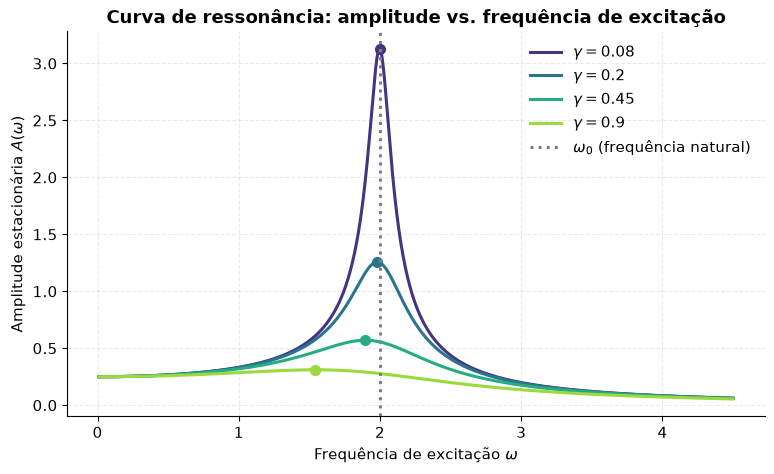

In [8]:
F0_m = 1.0  # F0/m
omega0_r = 2.0
omegas = np.linspace(0.01, 4.5, 1500)

def amplitude(omega, gamma, omega0=omega0_r, F0_m=F0_m):
    return F0_m/np.sqrt((omega0**2 - omega**2)**2 + (2*gamma*omega)**2)

gammas_res = [0.08, 0.2, 0.45, 0.9]
cmap2 = plt.cm.viridis(np.linspace(0.15, 0.85, len(gammas_res)))

fig, ax = plt.subplots()
for g, c in zip(gammas_res, cmap2):
    A_curve = amplitude(omegas, g)
    ax.plot(omegas, A_curve, color=c, label=fr'$\gamma={g}$')
    omega_res = np.sqrt(max(omega0_r**2 - 2*g**2, 0))
    ax.plot(omega_res, amplitude(omega_res, g), 'o', color=c, ms=7)

ax.axvline(omega0_r, color='gray', ls=':', label=r'$\omega_0$ (frequência natural)')
ax.set_xlabel(r'Frequência de excitação $\omega$')
ax.set_ylabel(r'Amplitude estacionária $A(\omega)$')
ax.set_title('Curva de ressonância: amplitude vs. frequência de excitação')
ax.legend()
plt.show()


Observe: quanto **menor** o amortecimento $\gamma$, **maior e mais estreito** é o pico de ressonância, e ele
se desloca ligeiramente para frequências mais baixas que $\omega_0$ (o pico ocorre em
$\omega_{\rm res} = \sqrt{\omega_0^2 - 2\gamma^2}$, ver seção 2.4).

### 2.3 Defasagem entre força e resposta

A fase $\delta$ entre a força aplicada e a resposta do sistema varia suavemente de $0$ (excitação muito abaixo
da ressonância — resposta "em fase" com a força) até $\pi$ (excitação muito acima da ressonância — resposta
"fora de fase"), passando exatamente por $\pi/2$ em $\omega=\omega_0$.


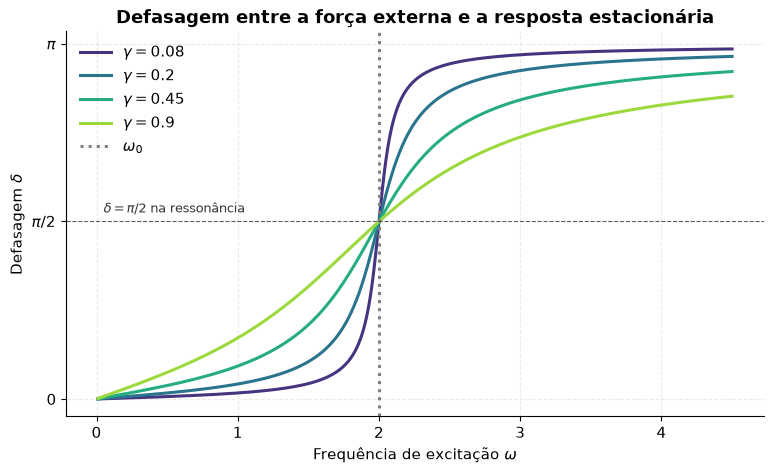

In [9]:
def fase(omega, gamma, omega0=omega0_r):
    num = 2*gamma*omega
    den = omega0**2 - omega**2
    d = np.arctan2(num, den)   # usa arctan2 para cobrir corretamente 0 a pi
    return d

fig, ax = plt.subplots()
for g, c in zip(gammas_res, cmap2):
    d_curve = fase(omegas, g)
    ax.plot(omegas, d_curve, color=c, label=fr'$\gamma={g}$')

ax.axvline(omega0_r, color='gray', ls=':', label=r'$\omega_0$')
ax.axhline(np.pi/2, color='k', ls='--', lw=0.8, alpha=0.6)
ax.text(0.05, np.pi/2+0.08, r'$\delta=\pi/2$ na ressonância', fontsize=9, alpha=0.8)
ax.set_yticks([0, np.pi/2, np.pi])
ax.set_yticklabels(['0', r'$\pi/2$', r'$\pi$'])
ax.set_xlabel(r'Frequência de excitação $\omega$')
ax.set_ylabel(r'Defasagem $\delta$')
ax.set_title('Defasagem entre a força externa e a resposta estacionária')
ax.legend()
plt.show()


> **Intuição física:** longe abaixo da ressonância, o sistema "acompanha" a força quase instantaneamente (fase
> ~0, como empurrar algo muito rígido devagar). Exatamente na ressonância, a resposta está 90° atrasada — é
> justamente essa defasagem que faz a força injetar energia de forma ótima no sistema a cada ciclo, alimentando o
> crescimento da amplitude. Muito acima da ressonância, o sistema mal consegue reagir e oscila em oposição de fase
> (atraso de 180°) com amplitude pequena — a inércia domina.

### 2.4 Ressonância: simulação dinâmica e exemplos reais

O pico de amplitude ocorre em $\omega_{\rm res} = \sqrt{\omega_0^2 - 2\gamma^2}$ (obtido maximizando $A(\omega)$).
Para $\gamma \to 0$, $\omega_{\rm res}\to\omega_0$ e a amplitude diverge — fisicamente, o sistema ganharia energia
sem limite a cada ciclo, até a estrutura falhar (ou efeitos não-lineares/dissipativos extras entrarem em jogo).

Isso tem analogias históricas marcantes em engenharia: o colapso da **ponte de Tacoma Narrows** (1940) é
popularmente associado a fenômenos de ressonância/instabilidade aeroelástica; estruturas offshore e embarcações
também são projetadas evitando que frequências de ondas/ventos coincidam com modos naturais de vibração da
estrutura.

Vamos simular numericamente (sem `scipy`, usando Runge-Kutta de 4ª ordem feito manualmente) a resposta de um
oscilador forçado perto e longe da ressonância.


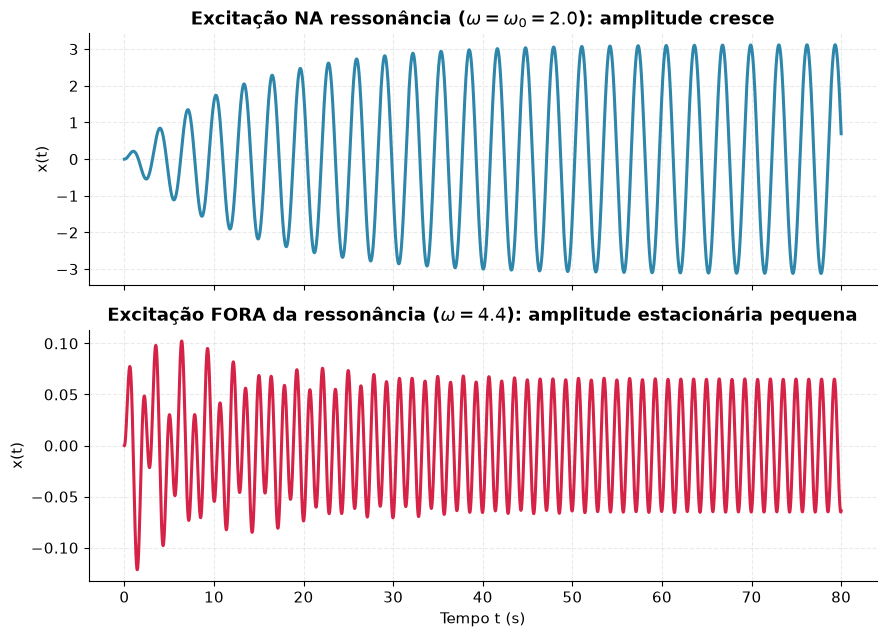

In [10]:
def rk4_forcado(gamma, omega0, omega_exc, F0_m, t_max, dt, x0=0.0, v0=0.0):
    n = int(t_max/dt)
    ts = np.linspace(0, t_max, n)
    xs = np.zeros(n); vs = np.zeros(n)
    xs[0], vs[0] = x0, v0

    def deriv(t, x, v):
        a = F0_m*np.cos(omega_exc*t) - 2*gamma*v - omega0**2*x
        return v, a

    for i in range(n-1):
        t = ts[i]
        k1x, k1v = deriv(t, xs[i], vs[i])
        k2x, k2v = deriv(t+dt/2, xs[i]+dt/2*k1x, vs[i]+dt/2*k1v)
        k3x, k3v = deriv(t+dt/2, xs[i]+dt/2*k2x, vs[i]+dt/2*k2v)
        k4x, k4v = deriv(t+dt, xs[i]+dt*k3x, vs[i]+dt*k3v)
        xs[i+1] = xs[i] + dt/6*(k1x+2*k2x+2*k3x+k4x)
        vs[i+1] = vs[i] + dt/6*(k1v+2*k2v+2*k3v+k4v)
    return ts, xs, vs

gamma_sim = 0.08
omega0_sim = 2.0
t_max, dt = 80, 0.01

ts_res, xs_res, _ = rk4_forcado(gamma_sim, omega0_sim, omega_exc=omega0_sim, F0_m=1.0, t_max=t_max, dt=dt)
ts_off, xs_off, _ = rk4_forcado(gamma_sim, omega0_sim, omega_exc=omega0_sim*2.2, F0_m=1.0, t_max=t_max, dt=dt)

fig, axs = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
axs[0].plot(ts_res, xs_res, color=COR_SUB)
axs[0].set_title(fr'Excitação NA ressonância ($\omega=\omega_0={omega0_sim}$): amplitude cresce')
axs[0].set_ylabel('x(t)')

axs[1].plot(ts_off, xs_off, color=COR_SUPER)
axs[1].set_title(fr'Excitação FORA da ressonância ($\omega={omega0_sim*2.2:.1f}$): amplitude estacionária pequena')
axs[1].set_xlabel('Tempo t (s)')
axs[1].set_ylabel('x(t)')
plt.tight_layout()
plt.show()


In [11]:
# Animação comparando os dois casos lado a lado: massa-mola com amplitude crescendo na ressonância
# vs. amplitude pequena fora da ressonância
step = 25
frames_idx = np.arange(0, len(ts_res), step)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, titulo in zip([ax1, ax2], ['Na ressonância ($\\omega=\\omega_0$)', 'Fora da ressonância']):
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-0.6, 0.6)
    ax.set_yticks([]); ax.set_title(titulo)
    ax.plot([-2.2, 2.2], [0, 0], color='gray', lw=0.8)

massa1 = plt.Circle((0, 0), 0.12, color=COR_SUB, zorder=5)
massa2 = plt.Circle((0, 0), 0.12, color=COR_SUPER, zorder=5)
ax1.add_patch(massa1); ax2.add_patch(massa2)
seta1 = ax1.annotate('', xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle='->', color=COR_FORCA, lw=2))
seta2 = ax2.annotate('', xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle='->', color=COR_FORCA, lw=2))

scale = 0.8  # fator visual (amplitude real cresce bastante na ressonância, truncamos)

def update2(i):
    idx = frames_idx[i]
    x1 = np.clip(xs_res[idx]*scale, -2.0, 2.0)
    x2 = xs_off[idx]*scale*3  # amplifica um pouco para visibilidade (ainda bem menor que x1 em módulo real)
    massa1.center = (x1, 0)
    massa2.center = (x2, 0)
    f1 = 0.5*np.cos(omega0_sim*ts_res[idx])
    f2 = 0.5*np.cos(omega0_sim*2.2*ts_off[idx])
    seta1.set_position((x1-np.sign(f1)*0.35, 0)); seta1.xy = (x1 - np.sign(f1)*0.35 + f1*0.4, 0)
    seta2.set_position((x2-np.sign(f2)*0.35, 0)); seta2.xy = (x2 - np.sign(f2)*0.35 + f2*0.4, 0)
    return massa1, massa2, seta1, seta2

anim2 = animation.FuncAnimation(fig, update2, frames=len(frames_idx), interval=35, blit=False)
plt.close(fig)
HTML(anim2.to_jshtml())


> **Intuição física:** note como, na ressonância, a amplitude cresce ciclo após ciclo (até o amortecimento
> equilibrar a energia injetada pela força, atingindo o regime estacionário de pico alto) — é exatamente esse
> mecanismo de "bombeamento" contínuo de energia em fase que tornou a ressonância um risco estrutural em pontes,
> prédios e estruturas offshore quando a frequência de excitação (vento, ondas, máquinas) se aproxima de um modo
> natural da estrutura.


### 2.5 Papel das condições iniciais: transiente + estacionário

A solução completa da equação forçada é a soma de duas partes:

$$x(t) = \underbrace{x_h(t)}_{\text{transiente amortecido (depende das condições iniciais)}} + \underbrace{x_{\rm est}(t)}_{\text{estacionária (não depende das condições iniciais)}}$$

O termo $x_h(t)$ é uma solução da equação *homogênea* (seção 1), que decai como $e^{-\gamma t}$. Depois de um
tempo da ordem de $1/\gamma$, esse termo torna-se desprezível e **só resta a oscilação estacionária**,
independentemente de como o sistema partiu. Vamos comprovar isso simulando duas condições iniciais bem
diferentes e mostrando que ambas convergem para a mesma curva estacionária.


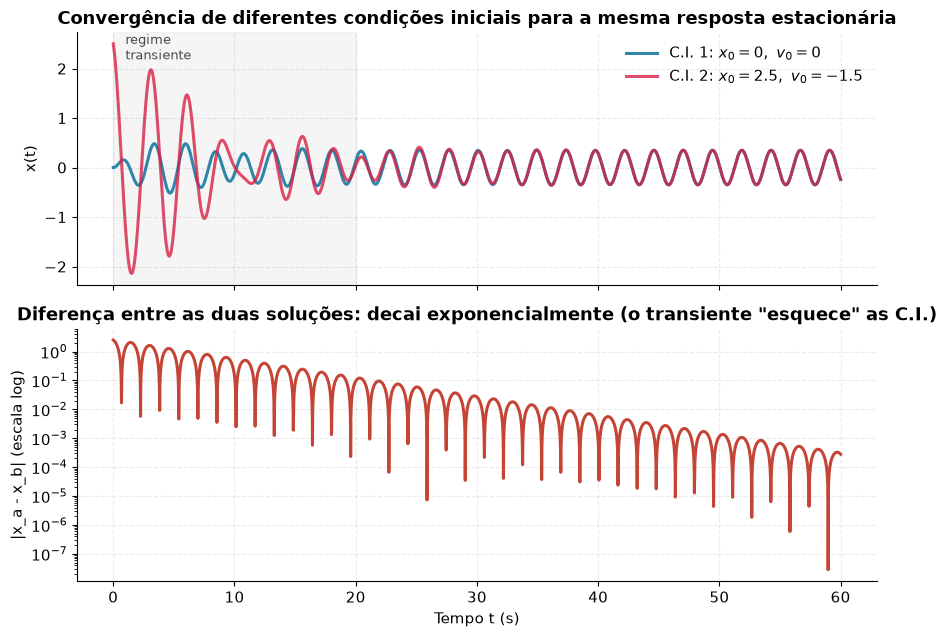

Tempo característico do transiente: ~1/gamma = 6.7 s
Após alguns múltiplos desse tempo, as duas curvas (de C.I. bem diferentes) tornam-se indistinguíveis.


In [12]:
gamma_ci = 0.15
omega0_ci = 2.0
omega_exc_ci = 2.6
t_max2, dt2 = 60, 0.01

ts_a, xs_a, _ = rk4_forcado(gamma_ci, omega0_ci, omega_exc_ci, F0_m=1.0, t_max=t_max2, dt=dt2, x0=0.0, v0=0.0)
ts_b, xs_b, _ = rk4_forcado(gamma_ci, omega0_ci, omega_exc_ci, F0_m=1.0, t_max=t_max2, dt=dt2, x0=2.5, v0=-1.5)

fig, axs = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
axs[0].plot(ts_a, xs_a, color=COR_SUB, label='C.I. 1: $x_0=0,\\ v_0=0$')
axs[0].plot(ts_b, xs_b, color=COR_SUPER, alpha=0.8, label='C.I. 2: $x_0=2.5,\\ v_0=-1.5$')
axs[0].set_title('Convergência de diferentes condições iniciais para a mesma resposta estacionária')
axs[0].set_ylabel('x(t)')
axs[0].legend(loc='upper right')
axs[0].axvspan(0, 3/gamma_ci, color='gray', alpha=0.08)
axs[0].text(1, axs[0].get_ylim()[1]*0.8, 'regime\ntransiente', fontsize=9, alpha=0.7)

diff = np.abs(xs_a - xs_b)
axs[1].plot(ts_a, diff, color=COR_ENERGIA)
axs[1].set_yscale('log')
axs[1].set_xlabel('Tempo t (s)')
axs[1].set_ylabel('|x_a - x_b| (escala log)')
axs[1].set_title('Diferença entre as duas soluções: decai exponencialmente (o transiente "esquece" as C.I.)')
plt.tight_layout()
plt.show()

print(f'Tempo característico do transiente: ~1/gamma = {1/gamma_ci:.1f} s')
print('Após alguns múltiplos desse tempo, as duas curvas (de C.I. bem diferentes) tornam-se indistinguíveis.')


> **Intuição física:** isso ilustra um resultado geral e poderoso de sistemas lineares amortecidos e forçados: a
> "memória" das condições iniciais desaparece exponencialmente rápido. Na prática de engenharia, isso significa
> que, ao analisar a resposta de longo prazo de uma estrutura sob carga periódica (ondas, vibração de máquinas),
> só o regime estacionário importa — como o sistema foi colocado em movimento no início é irrelevante.


## Resumo final

| Conceito | Resultado-chave |
|---|---|
| Oscilador amortecido | $\ddot x + 2\gamma\dot x + \omega_0^2 x = 0$; regimes sub/crítico/super conforme $\gamma \lessgtr \omega_0$ |
| Subamortecido | $x=Ae^{-\gamma t}\cos(\omega_d t+\phi)$; energia decai como $e^{-2\gamma t}$; $Q=\omega_0/2\gamma$ mede quantas oscilações até decair |
| Crítico | $(A+Bt)e^{-\gamma t}$: retorno mais rápido sem oscilar — ótimo para amortecedores/suspensões |
| Superamortecido | duas exponenciais reais; quanto mais amortecido, mais lento o retorno |
| Oscilador forçado | $\ddot x + 2\gamma\dot x+\omega_0^2 x = (F_0/m)\cos(\omega t)$; regime estacionário com amplitude $A(\omega)$ e fase $\delta(\omega)$ |
| Ressonância | pico de $A(\omega)$ perto de $\omega\approx\omega_0$; quanto menor $\gamma$, maior e mais estreito o pico; $\delta$ passa por $\pi/2$ exatamente na ressonância |
| Condições iniciais | solução completa = transiente (decai) + estacionária; após $\sim 1/\gamma$, só resta o regime estacionário |

Esses conceitos preparam o terreno para o próximo tópico do curso — **fenômenos ondulatórios** — onde
osciladores acoplados e forçados aparecem na forma de ondas propagantes em meios contínuos (cordas, fluidos,
estruturas).
